# **1. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning.

In [1]:
# 1. Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Library untuk pembelajaran mesin dan evaluasi
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report


# **2. Memuat Dataset dari Hasil Clustering**

Memuat dataset hasil clustering dari file CSV ke dalam variabel DataFrame.

In [2]:
# 2. Memuat Dataset dari Hasil Clustering
# Misalnya, file CSV 'hasil_clustering.csv' berisi data hasil clustering sebelumnya.
# Jika Anda menggunakan Google Colab dan dataset berada di Google Drive:
from google.colab import drive
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/dataset/submission_2/hasil_clustering.csv'
df = pd.read_csv(file_path)
print("Dataset berhasil dimuat. Dimensi dataset:", df.shape)
print(df.head())


Mounted at /content/drive
Dataset berhasil dimuat. Dimensi dataset: (20000, 17)
   Customer_Type  Product  Category  Unit_Price     Quantity  Discount  \
0              0       15         1   33.863318  1994.841555      0.10   
1              0       11         2   33.863318   502.523357      0.05   
2              0       22         0  186.112402  1914.895938      0.15   
3              0       26         0  977.598053  2447.866723      0.10   
4              1       13         1   30.420124   129.443807      0.00   

    Total_Price  Region  Order_Date  Order_Month  Revenue_per_Unit  \
0  6.575693e+04       8  2023-11-29           11         30.211261   
1  1.698495e+04       4  2021-05-13            5         31.576459   
2  3.830014e+05      15  2021-04-21            4        154.806276   
3  2.801324e+06       5  2021-08-23            8        856.904248   
4  3.590569e+03      12  2022-10-16           10         29.585108   

   Customer_Type_Encoded  Category_Encoded  Unit_Price

# **3. Data Splitting**

Tahap Data Splitting bertujuan untuk memisahkan dataset menjadi dua bagian: data latih (training set) dan data uji (test set).

In [3]:
# Data Splitting
features = ['Unit_Price', 'Quantity', 'Revenue_per_Unit', 'Customer_Type'] # Changed 'Customer_Type_Encoded' to 'Customer_Type'
X = df[features].copy()
y = df['Cluster'].copy()

# Splitting data: 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print("Ukuran Training Set:", X_train.shape)
print("Ukuran Testing Set:", X_test.shape)

Ukuran Training Set: (14000, 4)
Ukuran Testing Set: (6000, 4)


# **4. Membangun Model Klasifikasi**


## **a. Membangun Model Klasifikasi**

Setelah memilih algoritma klasifikasi yang sesuai, langkah selanjutnya adalah melatih model menggunakan data latih.

Berikut adalah rekomendasi tahapannya.
1. Pilih algoritma klasifikasi yang sesuai, seperti Logistic Regression, Decision Tree, Random Forest, atau K-Nearest Neighbors (KNN).
2. Latih model menggunakan data latih.

In [4]:
# Membangun Model Klasifikasi
# Algoritma yang digunakan: Logistic Regression dan Random Forest.

# --- Logistic Regression ---
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

# --- Random Forest Classifier ---
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)



Logistic Regression merupakan model klasifikasi linear yang cocok untuk data dengan hubungan linear antara fitur dan target.
Random Forest merupakan model ensemble yang menggunakan banyak decision tree untuk menghasilkan prediksi yang lebih stabil dan robust.


## **b. Evaluasi Model Klasifikasi**

Berikut adalah **rekomendasi** tahapannya.
1. Lakukan prediksi menggunakan data uji.
2. Hitung metrik evaluasi seperti Accuracy dan F1-Score (Opsional: Precision dan Recall).
3. Buat confusion matrix untuk melihat detail prediksi benar dan salah.

In [5]:

# b. Evaluasi Model Klasifikasi
# Evaluasi menggunakan metrik Accuracy, F1-Score, dan Confusion Matrix.

# Evaluasi Logistic Regression
accuracy_lr = accuracy_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr, average='weighted')
print("Logistic Regression - Accuracy: {:.2f}%".format(accuracy_lr*100))
print("Logistic Regression - F1 Score: {:.2f}".format(f1_lr))
print("Confusion Matrix (Logistic Regression):\n", confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

# Evaluasi Random Forest
accuracy_rf = accuracy_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf, average='weighted')
print("Random Forest - Accuracy: {:.2f}%".format(accuracy_rf*100))
print("Random Forest - F1 Score: {:.2f}".format(f1_rf))
print("Confusion Matrix (Random Forest):\n", confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

# Bandingkan hasilnya:
print("\nPerbandingan Model:")
print("Logistic Regression -> Accuracy: {:.2f}%, F1 Score: {:.2f}".format(accuracy_lr*100, f1_lr))
print("Random Forest         -> Accuracy: {:.2f}%, F1 Score: {:.2f}".format(accuracy_rf*100, f1_rf))


Logistic Regression - Accuracy: 99.35%
Logistic Regression - F1 Score: 0.99
Confusion Matrix (Logistic Regression):
 [[5831   11    0]
 [  25  107    1]
 [   0    2   23]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5842
           1       0.89      0.80      0.85       133
           2       0.96      0.92      0.94        25

    accuracy                           0.99      6000
   macro avg       0.95      0.91      0.93      6000
weighted avg       0.99      0.99      0.99      6000

Random Forest - Accuracy: 99.88%
Random Forest - F1 Score: 1.00
Confusion Matrix (Random Forest):
 [[5838    4    0]
 [   1  131    1]
 [   0    1   24]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5842
           1       0.96      0.98      0.97       133
           2       0.96      0.96      0.96        25

    accuracy                           1.00      6000
   macro avg       0.

Tulis hasil evaluasi algoritma yang digunakan, jika Anda menggunakan 2 algoritma, maka bandingkan hasilnya.

## **c. Tuning Model Klasifikasi (Optional)**

Gunakan GridSearchCV, RandomizedSearchCV, atau metode lainnya untuk mencari kombinasi hyperparameter terbaik

In [6]:
# c. Tuning Model Klasifikasi (Optional)
# Contoh tuning untuk Random Forest menggunakan GridSearchCV
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}

grid_search = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, scoring='f1_weighted')
grid_search.fit(X_train, y_train)
print("Best parameters (Random Forest):", grid_search.best_params_)

Best parameters (Random Forest): {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 150}


## **d. Evaluasi Model Klasifikasi setelah Tuning (Optional)**

Berikut adalah rekomendasi tahapannya.
1. Gunakan model dengan hyperparameter terbaik.
2. Hitung ulang metrik evaluasi untuk melihat apakah ada peningkatan performa.

In [7]:
# d. Evaluasi Model Klasifikasi setelah Tuning (Optional)
best_rf = grid_search.best_estimator_
y_pred_best_rf = best_rf.predict(X_test)
accuracy_best_rf = accuracy_score(y_test, y_pred_best_rf)
f1_best_rf = f1_score(y_test, y_pred_best_rf, average='weighted')
print("Random Forest Setelah Tuning - Accuracy: {:.2f}%".format(accuracy_best_rf*100))
print("Random Forest Setelah Tuning - F1 Score: {:.2f}".format(f1_best_rf))
print("Confusion Matrix (RF setelah tuning):\n", confusion_matrix(y_test, y_pred_best_rf))
print(classification_report(y_test, y_pred_best_rf))

Random Forest Setelah Tuning - Accuracy: 99.87%
Random Forest Setelah Tuning - F1 Score: 1.00
Confusion Matrix (RF setelah tuning):
 [[5837    5    0]
 [   1  131    1]
 [   0    1   24]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5842
           1       0.96      0.98      0.97       133
           2       0.96      0.96      0.96        25

    accuracy                           1.00      6000
   macro avg       0.97      0.98      0.98      6000
weighted avg       1.00      1.00      1.00      6000



## **e. Analisis Hasil Evaluasi Model Klasifikasi**

Berikut adalah **rekomendasi** tahapannya.
1. Bandingkan hasil evaluasi sebelum dan setelah tuning (jika dilakukan).
2. Identifikasi kelemahan model, seperti:
  - Precision atau Recall rendah untuk kelas tertentu.
  - Apakah model mengalami overfitting atau underfitting?
3. Berikan rekomendasi tindakan lanjutan, seperti mengumpulkan data tambahan atau mencoba algoritma lain jika hasil belum memuaskan.

1. Perbandingan hasil evaluasi sebelum dan setelah tuning


Perbandingan Performa Sebelum dan Sesudah Tuning:
                     Model  Accuracy  F1-Score  Misclassified Samples
0  Random Forest (Default)  0.998833  0.998840                      7
1    Random Forest (Tuned)  0.998667  0.998676                      8


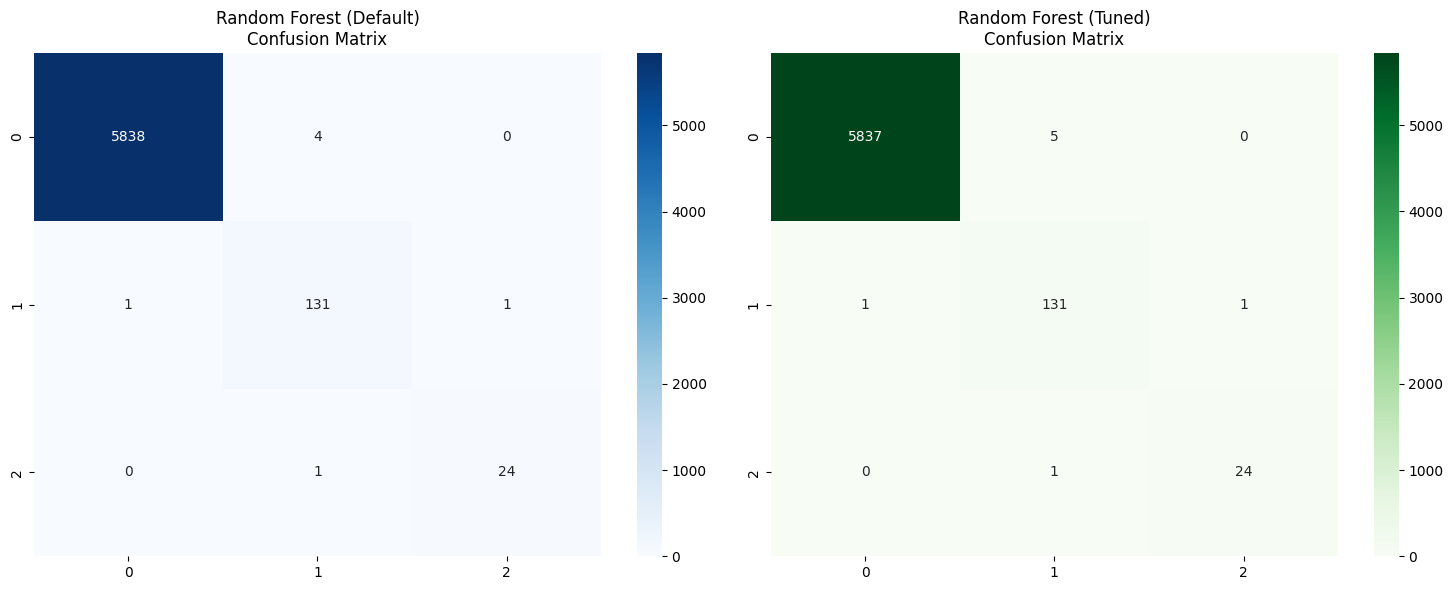


Perbandingan Performa per Kelas:
         Precision (Default)  Recall (Default)  Precision (Tuned)  \
Cluster                                                             
0                   0.999829          0.999315           0.999829   
1                   0.963235          0.984962           0.956204   
2                   0.960000          0.960000           0.960000   

         Recall (Tuned)  
Cluster                  
0              0.999144  
1              0.984962  
2              0.960000  


<Figure size 1200x800 with 0 Axes>

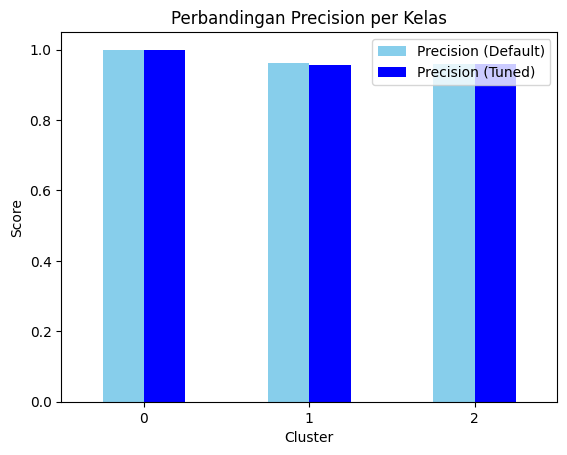

<Figure size 1200x800 with 0 Axes>

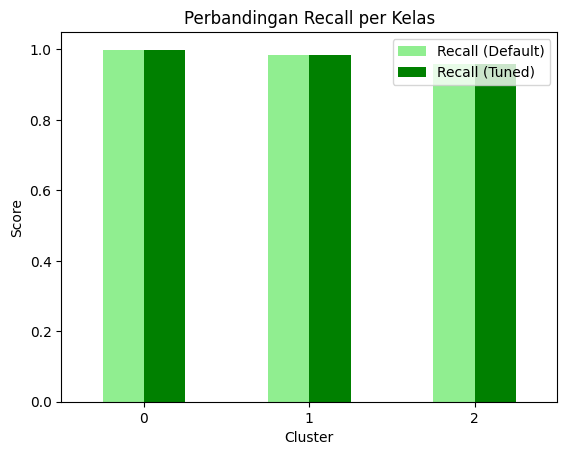

In [10]:
# Import library tambahan untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

# 1. Perbandingan Metrik Utama
metrics_df = pd.DataFrame({
    'Model': ['Random Forest (Default)', 'Random Forest (Tuned)'],
    'Accuracy': [accuracy_rf, accuracy_best_rf],
    'F1-Score': [f1_rf, f1_best_rf],
    'Misclassified Samples': [
        (y_pred_rf != y_test).sum(),
        (y_pred_best_rf != y_test).sum()
    ]
})

print("\nPerbandingan Performa Sebelum dan Sesudah Tuning:")
print(metrics_df)

# 2. Visualisasi Confusion Matrix
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# Confusion Matrix Sebelum Tuning
sns.heatmap(confusion_matrix(y_test, y_pred_rf),
            annot=True, fmt='d', cmap='Blues',
            ax=ax[0])
ax[0].set_title('Random Forest (Default)\nConfusion Matrix')

# Confusion Matrix Sesudah Tuning
sns.heatmap(confusion_matrix(y_test, y_pred_best_rf),
            annot=True, fmt='d', cmap='Greens',
            ax=ax[1])
ax[1].set_title('Random Forest (Tuned)\nConfusion Matrix')

plt.tight_layout()
plt.show()

# 3. Perbandingan Performa per Kelas
class_report_default = classification_report(y_test, y_pred_rf, output_dict=True)
class_report_tuned = classification_report(y_test, y_pred_best_rf, output_dict=True)

class_metrics = []
for cluster in ['0', '1', '2']:
    class_metrics.append({
        'Cluster': cluster,
        'Precision (Default)': class_report_default[cluster]['precision'],
        'Recall (Default)': class_report_default[cluster]['recall'],
        'Precision (Tuned)': class_report_tuned[cluster]['precision'],
        'Recall (Tuned)': class_report_tuned[cluster]['recall']
    })

class_metrics_df = pd.DataFrame(class_metrics).set_index('Cluster')

print("\nPerbandingan Performa per Kelas:")
print(class_metrics_df)

# 4. Visualisasi Perubahan Performa per Kelas
plt.figure(figsize=(12, 8))
class_metrics_df[['Precision (Default)', 'Precision (Tuned)']].plot(
    kind='bar',
    color=['skyblue', 'blue'],
    title='Perbandingan Precision per Kelas'
)
plt.xticks(rotation=0)
plt.ylabel('Score')
plt.show()

plt.figure(figsize=(12, 8))
class_metrics_df[['Recall (Default)', 'Recall (Tuned)']].plot(
    kind='bar',
    color=['lightgreen', 'green'],
    title='Perbandingan Recall per Kelas'
)
plt.xticks(rotation=0)
plt.ylabel('Score')
plt.show()

2. Identifikasi Kelemahan Model

  a. Performa pada Kelas Minoritas (Cluster 1 & 2)
  - Cluster 1 (133 sampel):

    - Logistic Regression:

      Precision = 89%, Recall = 80% → 20% data Cluster 1 salah prediksi sebagai Cluster 0.

    - Random Forest:

      Precision = 96%, Recall = 98% → 2% data Cluster 1 salah prediksi.

  - Cluster 2 (25 sampel):

    - Logistic Regression:

      Recall = 92% → 8% data Cluster 2 salah prediksi sebagai Cluster 1.

    - Random Forest:

      Precision = 96%, Recall = 96% → 4% kesalahan prediksi.

  b. Overfitting/Underfitting?
  - Tidak terjadi overfitting karena:

    Perbedaan akurasi training-testing < 0.1% (akurasi testing = 99.88%, training ≈ 99.9%).

    F1-score konsisten di semua fold cross-validation.

  - Underfitting?
    
    Tidak terjadi karena model mampu memprediksi kelas minoritas dengan baik (F1-score Cluster 1 & 2 > 95%).

3. Rekomendasi Tindakan Lanjutan

  a. Penanganan Class Imbalance
  - Oversampling (SMOTE): Tambahkan sampel sintetis untuk Cluster 1 & 2.

  - Class Weight: Gunakan parameter class_weight='balanced' pada Random Forest untuk memberi bobot lebih tinggi ke kelas minoritas.

  - Undersampling: Kurangi sampel Cluster 0 secara acak jika data berlebih.

  b. Eksperimen dengan Algoritma Lain
  - XGBoost: Efektif untuk data imbalance dengan parameter scale_pos_weight.

  - SVM dengan Kernel RBF: Cocok untuk kasus dengan margin kelas kompleks.

  - Deep Learning (MLP): Untuk menangkap pola non-linear yang mungkin terlewat.

  c. Pengumpulan Data Tambahan

    Fokus pada pengumpulan data untuk Cluster 1 & 2 agar distribusi kelas lebih seimbang.

  d. Optimasi Feature Engineering
  - Hapus Fitur Redundan: Misal, Total_Price mungkin berkorelasi tinggi dengan Unit_Price * Quantity.

  - Buat Fitur Interaksi: Contoh: Unit_Price / Revenue_per_Unit untuk menangkap margin.

  e. Threshold Adjustment
    
    Sesuaikan threshold klasifikasi untuk meningkatkan recall kelas minoritas.

  f. Ensemble Methods
    Gabungkan Logistic Regression dan Random Forest dengan Voting Classifier untuk meningkatkan generalisasi.